# HW 8, Problem 3: Stochastic ensemble Kalman filter

Both models, with the truth, observations, $H$, $R$, $D$, and prior saved in Problem 1 (`data/hw8_twin_*.npz`); nothing is regenerated here. The filter is the HW 7 stochastic EnKF (`src/da_models/enkf.py`), adapted as described below.

## Setup

* **Forecast.** Every member is advanced from $t_{k-1}$ to $t_k$ with $\mathcal M_{k-1}$, the same deterministic model and solver as the truth and the EKF (`solve_ivp`, RK45, `rtol = atol = 1e-9`, $\delta t = 0.1$). All members go through one stacked `solve_ivp` call per window: the members do not interact, so this is the same ODE solved for every member with shared adaptive steps. The check below compares it with a member-by-member loop. $Q_{k-1} = 0$; no inflation, no localization.
* **Adaptations from HW 7.** `lorenz96.rhs` and `rhs_two_layer` now act along the state axis (`np.roll(..., axis=0)`), so a stacked $(n, N_e)$ ensemble is evaluated member by member (single-state results are unchanged bit for bit). `run_enkf` now records a solver failure or non-finite member, with its step $k$, instead of stopping with an error.
* **Initial ensemble.** $N_e$ independent draws from $N(m_0^a, P_0^a)$, the Problem 1 prior.
* **Analysis.** With $P^f_{k,e}$ the sample forecast covariance (denominator $N_e - 1$) and the same $H$, $R$ as the EKF,
$$K_{k,e} = P^f_{k,e}H^T\big(HP^f_{k,e}H^T + R\big)^{-1}, \qquad x_k^{a,(i)} = x_k^{f,(i)} + K_{k,e}\big(y_k + v_k^{(i)} - Hx_k^{f,(i)}\big), \qquad v_k^{(i)} \sim N(0, R)\ \text{i.i.d.}$$
The gain comes from solving $S\,K_{k,e}^T = HP^f_{k,e}$, $S = HP^f_{k,e}H^T + R$ (no inverse). The analysis mean $\bar x_k^a$ and covariance $P^a_{k,e}$ are recomputed from the updated members.
* **Experiments.** $N_e = 50$ and $200$ for both models, each with three replicates $r = 0, 1, 2$.
* **Random streams** (separate generators; `model` = 0 for one-layer, 1 for two-layer): data `default_rng([513, 0, model])` (used once, in Problem 1); initial members `default_rng([513, 1, model, Ne, r])`; observation perturbations `default_rng([513, 2, model, Ne, r])`. Every seed is listed in the table in (a).
* **State domain.** Lorenz–96 has no restricted domain. Every member is checked for finite values at initialization and after every forecast and analysis; a failure would be reported with its time, never clipped or dropped.
* **Runtime.** Wall time of the whole cycle: forecasts of all members, analyses, and recomputing the ensemble mean and covariance, reported as the best of 3 identical runs (same seeds, so identical results). For reference, one run per model ($N_e = 50$, $r = 0$) is also timed with a member-by-member forecast loop.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from da_models import hw8, lorenz96
from da_models.enkf import draw_initial_ensemble, run_enkf, ensemble_mean_cov
from da_models.kalman import run_kf, synthetic_observations
from scipy.linalg import expm

DATA_DIR = Path("../data")   # adjust if running in Colab
NAMES = ("l96", "l96_2layer")
ENSEMBLE_SIZES = hw8.ENSEMBLE_SIZES   # (50, 200)
REPLICATES = hw8.REPLICATES           # (0, 1, 2)
REPEATS = 3                           # timing: best of REPEATS identical runs

models = {name: hw8.load_model(name, DATA_DIR) for name in NAMES}
twins = {name: hw8.load_twin(name, DATA_DIR) for name in NAMES}
L = hw8.L
t_an = hw8.DT_OBS * np.arange(L + 1)      # t_0, ..., t_L
t_obs = t_an[1:]                          # t_1, ..., t_L

np.set_printoptions(precision=4, suppress=True, linewidth=110)
C = dict(truth="#0b0b0b", mean="#2a78d6", free="#8c8a85", obs="#eb6834", fc="#8c8a85", an="#2a78d6")
REP_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]      # replicates r = 0, 1, 2 (fixed order)
plt.rcParams.update({
    "axes.grid": True, "grid.color": "0.9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 1.2, "legend.frameon": False, "figure.dpi": 110,
})

def time_avg_rmse(rmse):
    # sqrt( L^{-1} sum_{k=1}^{L} RMSE_k^2 ); rmse[0] is the initial time and is excluded
    return np.sqrt(np.mean(rmse[1:] ** 2))

def seed_init(name, Ne, r):
    return [hw8.SEED, 1, NAMES.index(name), Ne, r]

def seed_pert(name, Ne, r):
    return [hw8.SEED, 2, NAMES.index(name), Ne, r]

## Checks

1. The adapted right-hand sides evaluate a stacked $(n, N_e)$ ensemble exactly as they evaluate each column separately.
2. Over one observation window, the stacked forecast agrees with a member-by-member loop to the solver tolerance.
3. On the **linear** model from Problem 2 ($\dot x = Ax$, $\mathbf M = e^{A\,\delta t}$, half the state observed, 30 analyses), the EnKF should approach the Kalman filter as $N_e$ grows, with differences shrinking like $N_e^{-1/2}$ (so the "$\times\sqrt{N_e}$" columns should stay roughly constant). A single run is noisy, so the table reports the median over 6 independent seeds. This tests the adapted `run_enkf` separately from the nonlinear models.

In [2]:
rng = np.random.default_rng(0)
for name, mdl in models.items():
    E = draw_initial_ensemble(mdl["m0"], mdl["P0"], 7, rng)
    stacked = mdl["rhs"](0, E, **mdl["params"])
    columns = np.column_stack([mdl["rhs"](0, E[:, i], **mdl["params"]) for i in range(7)])
    a, b = mdl["propagate_ens"](E), mdl["propagate_ens_loop"](E)
    print(f"{mdl['title']}: rhs stacked == column by column: {np.array_equal(stacked, columns)};  "
          f"one window, stacked vs loop: max |difference| = {np.abs(a - b).max():.1e} "
          f"(relative {np.abs(a - b).max() / np.abs(b).max():.1e})")

# linear model from Problem 2
rng = np.random.default_rng(0)
A_lin = 0.5 * rng.standard_normal((6, 6)) - 0.3 * np.eye(6)
M_lin, H_lin, R_lin = expm(A_lin * hw8.DT_OBS), np.eye(6)[::2], 0.5 * np.eye(3)
x_lin = [rng.standard_normal(6)]
for _ in range(30):
    x_lin.append(M_lin @ x_lin[-1])
Y_lin = synthetic_observations(np.array(x_lin), H_lin, R_lin, rng)
m0_lin, P0_lin = x_lin[0] + 0.3, 0.2 * np.eye(6)
kf_lin = run_kf(M_lin, H_lin, R_lin, Y_lin, m0_lin, P0_lin)
propagate_lin = lambda E: np.stack([E, M_lin @ E])          # (n_sub+1 = 2, n, Ne)

print(f"\nlinear model, EnKF vs KF at the last analysis (median over 6 seeds):")
print(f"{'Ne':>8}{'max |mean diff|':>18}{'x sqrt(Ne)':>12}{'max |cov diff|':>17}{'x sqrt(Ne)':>12}")
for Ne in (100, 1000, 10000):
    mean_diff, cov_diff = [], []
    for s in range(6):
        E0 = draw_initial_ensemble(m0_lin, P0_lin, Ne, np.random.default_rng([1, Ne, s]))
        o = run_enkf(propagate_lin, E0, Y_lin, H_lin, R_lin, np.random.default_rng([2, Ne, s]))
        mean_diff.append(np.abs(o["mean_a"][-1] - kf_lin["m_a"][-1]).max())
        cov_diff.append(np.abs(o["cov_a"][-1] - kf_lin["P_a"][-1]).max())
    md_, cd_ = np.median(mean_diff), np.median(cov_diff)
    print(f"{Ne:8d}{md_:18.4f}{md_ * np.sqrt(Ne):12.2f}{cd_:17.4f}{cd_ * np.sqrt(Ne):12.2f}")

One-layer Lorenz-96: rhs stacked == column by column: True;  one window, stacked vs loop: max |difference| = 5.3e-09 (relative 4.6e-10)
Two-layer Lorenz-96 (K = 10, J = 2): rhs stacked == column by column: True;  one window, stacked vs loop: max |difference| = 4.2e-09 (relative 4.9e-10)

linear model, EnKF vs KF at the last analysis (median over 6 seeds):
      Ne   max |mean diff|  x sqrt(Ne)   max |cov diff|  x sqrt(Ne)
     100            0.1007        1.01           0.0692        0.69


    1000            0.0246        0.78           0.0191        0.61


   10000            0.0157        1.57           0.0057        0.57


## (a) Runs, seeds, and runtimes

Every run uses the saved truth and data. The time-aggregated RMSE $\sqrt{L^{-1}\sum_{k=1}^L \mathrm{RMSE}_k^2}$ and the mean spread (scaled by $D$, as defined in Problem 4) are included for orientation; the full comparison is in Problem 4.

In [3]:
def timed_enkf(mdl, Y, Ne, r, propagate, repeats=REPEATS):
    # Best wall time of `repeats` runs. Every repeat redraws the initial ensemble and the
    # perturbations from fresh copies of the same streams, so all repeats give identical results.
    best = None
    for _ in range(repeats):
        E0 = draw_initial_ensemble(mdl["m0"], mdl["P0"], Ne, hw8.rng_init(mdl["name"], Ne, r))
        out = run_enkf(propagate, E0, Y, mdl["H"], mdl["R"], hw8.rng_pert(mdl["name"], Ne, r))
        if best is None or out["wall_time"] < best["wall_time"]:
            best = out
    return best

runs = {}    # (name, Ne, r) -> result
for name, mdl in models.items():
    tw = twins[name]
    for Ne in ENSEMBLE_SIZES:
        for r in REPLICATES:
            out = timed_enkf(mdl, tw["Y"], Ne, r, mdl["propagate_ens"])
            out["rmse"], out["spread"] = hw8.scaled_rmse_spread(out["mean_a"], tw["x_true"], mdl["D"], out["cov_a"])
            runs[(name, Ne, r)] = out

print(f"{'model':<36}{'Ne':>4}{'r':>3}  {'initial-ensemble seed':<24}{'perturbation seed':<22}"
      f"{'runtime (s)':>11}{'status':>11}{'time-agg RMSE':>15}{'mean spread':>13}")
for (name, Ne, r), o in runs.items():
    status = "completed" if o["failed_at"] is None else f"FAILED k={o['failed_at']}"
    print(f"{models[name]['title']:<36}{Ne:4d}{r:3d}  {str(seed_init(name, Ne, r)):<24}"
          f"{str(seed_pert(name, Ne, r)):<22}{o['wall_time']:11.2f}{status:>11}"
          f"{time_avg_rmse(o['rmse']):15.3f}{o['spread'][1:].mean():13.3f}")
n_bad = sum(int(not np.all(np.isfinite(o["E_a"]))) + int(not np.all(np.isfinite(o["E_f"][1:]))) for o in runs.values())
print(f"\nruns with any non-finite member (initial, forecast, or analysis): {n_bad}")
print(f"data stream (Problem 1): default_rng([513, 0, model]), model = 0 (one-layer), 1 (two-layer)")

model                                 Ne  r  initial-ensemble seed   perturbation seed     runtime (s)     status  time-agg RMSE  mean spread
One-layer Lorenz-96                   50  0  [513, 1, 0, 50, 0]      [513, 2, 0, 50, 0]           1.14  completed          0.371        0.093
One-layer Lorenz-96                   50  1  [513, 1, 0, 50, 1]      [513, 2, 0, 50, 1]           1.16  completed          0.175        0.093
One-layer Lorenz-96                   50  2  [513, 1, 0, 50, 2]      [513, 2, 0, 50, 2]           1.16  completed          0.185        0.093
One-layer Lorenz-96                  200  0  [513, 1, 0, 200, 0]     [513, 2, 0, 200, 0]          2.11  completed          0.109        0.103
One-layer Lorenz-96                  200  1  [513, 1, 0, 200, 1]     [513, 2, 0, 200, 1]          2.11  completed          0.110        0.103
One-layer Lorenz-96                  200  2  [513, 1, 0, 200, 2]     [513, 2, 0, 200, 2]          2.10  completed          0.115        0.104
Two-la

Reference timing: the same run with a member-by-member forecast loop ($N_e$ separate `solve_ivp` calls per window instead of one stacked call). In each window the two forecasts differ only at the solver tolerance (check 2 above); over 100 cycles the chaotic dynamics enlarge that difference somewhat, so the analysis means are compared too. Only the cost differs materially.

In [4]:
NE_LOOP, R_LOOP = 50, 0
for name, mdl in models.items():
    tw = twins[name]
    loop = timed_enkf(mdl, tw["Y"], NE_LOOP, R_LOOP, mdl["propagate_ens_loop"], repeats=1)
    stacked = runs[(name, NE_LOOP, R_LOOP)]
    diff = np.abs((loop["mean_a"] - stacked["mean_a"]) / mdl["D"]).max()
    print(f"{mdl['title']}, Ne = {NE_LOOP}, r = {R_LOOP}: member loop {loop['wall_time']:.1f} s vs "
          f"stacked {stacked['wall_time']:.2f} s;  max |D^-1 (mean_a loop - mean_a stacked)| = {diff:.1e}")

One-layer Lorenz-96, Ne = 50, r = 0: member loop 38.5 s vs stacked 1.14 s;  max |D^-1 (mean_a loop - mean_a stacked)| = 2.9e-06


Two-layer Lorenz-96 (K = 10, J = 2), Ne = 50, r = 0: member loop 44.6 s vs stacked 1.13 s;  max |D^-1 (mean_a loop - mean_a stacked)| = 1.5e-09


### RMSE and spread for every replicate

Scaled $\mathrm{RMSE}_k$ (solid) and $\mathrm{Spread}_k$ (dashed) at the analysis times; colors are replicates. The gray line is the RMSE of the free forecast.

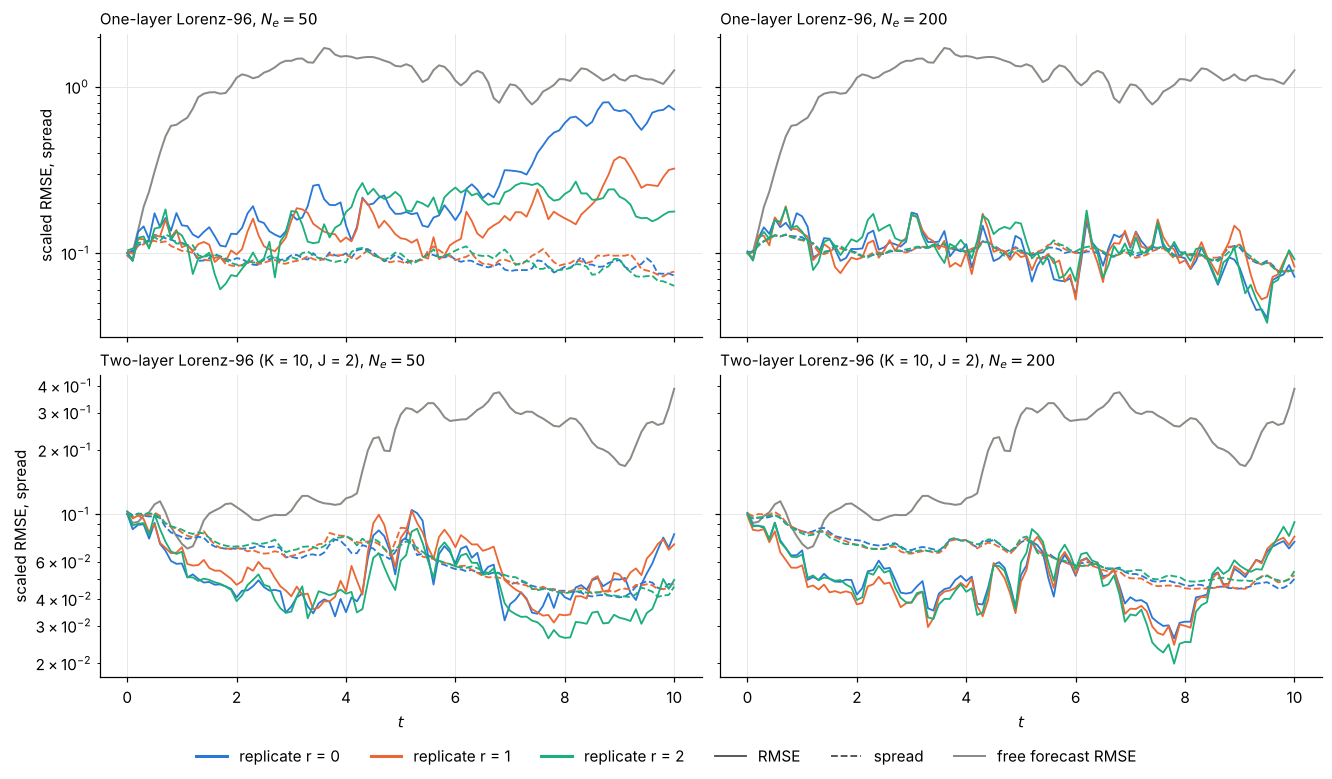

In [5]:
fig, axes = plt.subplots(len(NAMES), len(ENSEMBLE_SIZES), figsize=(12, 7), sharex=True,
                         sharey="row", constrained_layout=True, squeeze=False)
for i, (name, mdl) in enumerate(models.items()):
    tw = twins[name]
    rmse_free, _ = hw8.scaled_rmse_spread(tw["x_free"], tw["x_true"], mdl["D"])
    for j, Ne in enumerate(ENSEMBLE_SIZES):
        ax = axes[i, j]
        ax.semilogy(t_an, rmse_free, color=C["free"], lw=1.3)
        for r, color in zip(REPLICATES, REP_COLORS):
            o = runs[(name, Ne, r)]
            ax.semilogy(t_an, o["rmse"], color=color)
            ax.semilogy(t_an, o["spread"], color=color, ls="--")
        ax.set_title(f"{mdl['title']}, $N_e = {Ne}$", loc="left", fontsize=10)
    axes[i, 0].set_ylabel("scaled RMSE, spread")
for ax in axes[-1]:
    ax.set_xlabel("$t$")
handles = [Line2D([], [], color=c, lw=2, label=f"replicate r = {r}") for r, c in zip(REPLICATES, REP_COLORS)]
handles += [Line2D([], [], color="0.3", label="RMSE"), Line2D([], [], color="0.3", ls="--", label="spread"),
            Line2D([], [], color=C["free"], lw=1.3, label="free forecast RMSE")]
fig.legend(handles=handles, loc="outside lower center", ncol=6)
plt.show()

## (b) How the ensemble gain updates a hidden variable

Run $N_e = 200$, $r = 0$ (set `NE_SHOW`, `R_SHOW`, `K_SHOW`, or `HIDDEN` to look at another case), at the same analysis time and hidden components as Problem 2. For hidden component $i$, the cell prints the forecast-ensemble correlations with each observed component, row $i$ of $K_{k,e}$, the mean innovation $\bar d_k = y_k - H\bar x_k^f$, and the products $K_{k,e,ij}\bar d_{k,j}$. Because each member also receives its own perturbation, the change in the ensemble mean is
$$\bar x_k^a - \bar x_k^f = K_{k,e}\,\bar d_k + K_{k,e}\,\bar v_k, \qquad \bar v_k = \frac{1}{N_e}\sum_i v_k^{(i)},$$
and both terms are printed, along with the increments of a few individual members.

In [6]:
NE_SHOW, R_SHOW = 200, 0
K_SHOW = 50                                       # analysis index k, t_k = k * dt
HIDDEN = {"l96": "u1", "l96_2layer": "v0,1"}      # same hidden components as Problem 2
N_MEMBERS_SHOW = 4

for name, mdl in models.items():
    o, tw = runs[(name, NE_SHOW, R_SHOW)], twins[name]
    k, i = K_SHOW, mdl["labels"].index(HIDDEN[name])
    obs = mdl["observed"]
    obs_labels = [mdl["labels"][j] for j in obs]
    row, d_bar = o["K"][k - 1][i], o["innovation_mean"][k - 1]
    Pf = o["cov_f"][k]
    sd = np.sqrt(np.diag(Pf))
    corr = Pf[i, obs] / (sd[i] * sd[obs])
    D_mem = o["innovations"][k - 1]                         # (p, Ne): y + v^(i) - H x_f^(i)
    Ef = o["E_f"][k]
    v_bar = (D_mem + mdl["H"] @ Ef).mean(axis=1) - tw["Y"][k - 1]  # mean perturbation
    print(f"=== {mdl['title']}, Ne = {NE_SHOW}, r = {R_SHOW}: analysis k = {k} (t = {t_an[k]:.1f}), "
          f"hidden component {HIDDEN[name]} ===")
    print(f"truth {tw['x_true'][k, i]:.4f}   forecast mean {o['mean_f'][k, i]:.4f}   analysis mean {o['mean_a'][k, i]:.4f}")
    print(f"forecast ensemble sd {sd[i]:.4f}   analysis ensemble sd {np.sqrt(o['cov_a'][k][i, i]):.4f}")
    print(f"{'observed':>9}{'corr_f':>9}{'K row':>10}{'d_bar':>9}{'K*d_bar':>10}")
    for lab, c, kk, dd in zip(obs_labels, corr, row, d_bar):
        print(f"{lab:>9}{c:9.3f}{kk:10.4f}{dd:9.3f}{kk * dd:10.4f}")
    print(f"K d_bar = {row @ d_bar:.4f};  K v_bar = {row @ v_bar:.4f};  sum = {row @ (d_bar + v_bar):.4f};  "
          f"mean_a - mean_f = {o['mean_a'][k, i] - o['mean_f'][k, i]:.4f}")
    print(f"first {N_MEMBERS_SHOW} members: forecast {Ef[i, :N_MEMBERS_SHOW]},  increment "
          f"{(o['E_a'][k] - Ef)[i, :N_MEMBERS_SHOW]}\n")

=== One-layer Lorenz-96, Ne = 200, r = 0: analysis k = 50 (t = 5.0), hidden component u1 ===
truth 1.4040   forecast mean 1.4368   analysis mean 1.2714
forecast ensemble sd 0.6959   analysis ensemble sd 0.6678
 observed   corr_f     K row    d_bar   K*d_bar
       u0   -0.151   -0.0104    0.950   -0.0099
       u2    0.163    0.0243    0.685    0.0166
       u4    0.873    0.1745    0.082    0.0143
       u6    0.128    0.0115   -1.211   -0.0139
       u8   -0.254   -0.0505    1.691   -0.0854
      u10   -0.187   -0.0190   -0.090    0.0017
      u12    0.191    0.0436    0.430    0.0188
      u14    0.159    0.0096    0.289    0.0028
      u16   -0.023    0.0029    0.150    0.0004
      u18    0.063    0.0058    0.705    0.0041
      u20   -0.044   -0.0044   -0.290    0.0013
      u22    0.045    0.0083    0.548    0.0045
      u24   -0.006    0.0027    0.393    0.0011
      u26   -0.016   -0.0060   -0.281    0.0017
      u28    0.080    0.0147   -1.133   -0.0166
      u30   -0.047   -

Left to right: row $i$ of $K_{k,e}$; the mean innovation; the contributions $K_{k,e,ij}\bar d_{k,j}$; and the forecast and analysis members in the plane of the hidden component and the observed component that contributes most, with the observation $y_{k,j}$ (vertical line) and the truth (star). The second figure shows the hidden component's mean increment against its forecast error at every analysis.

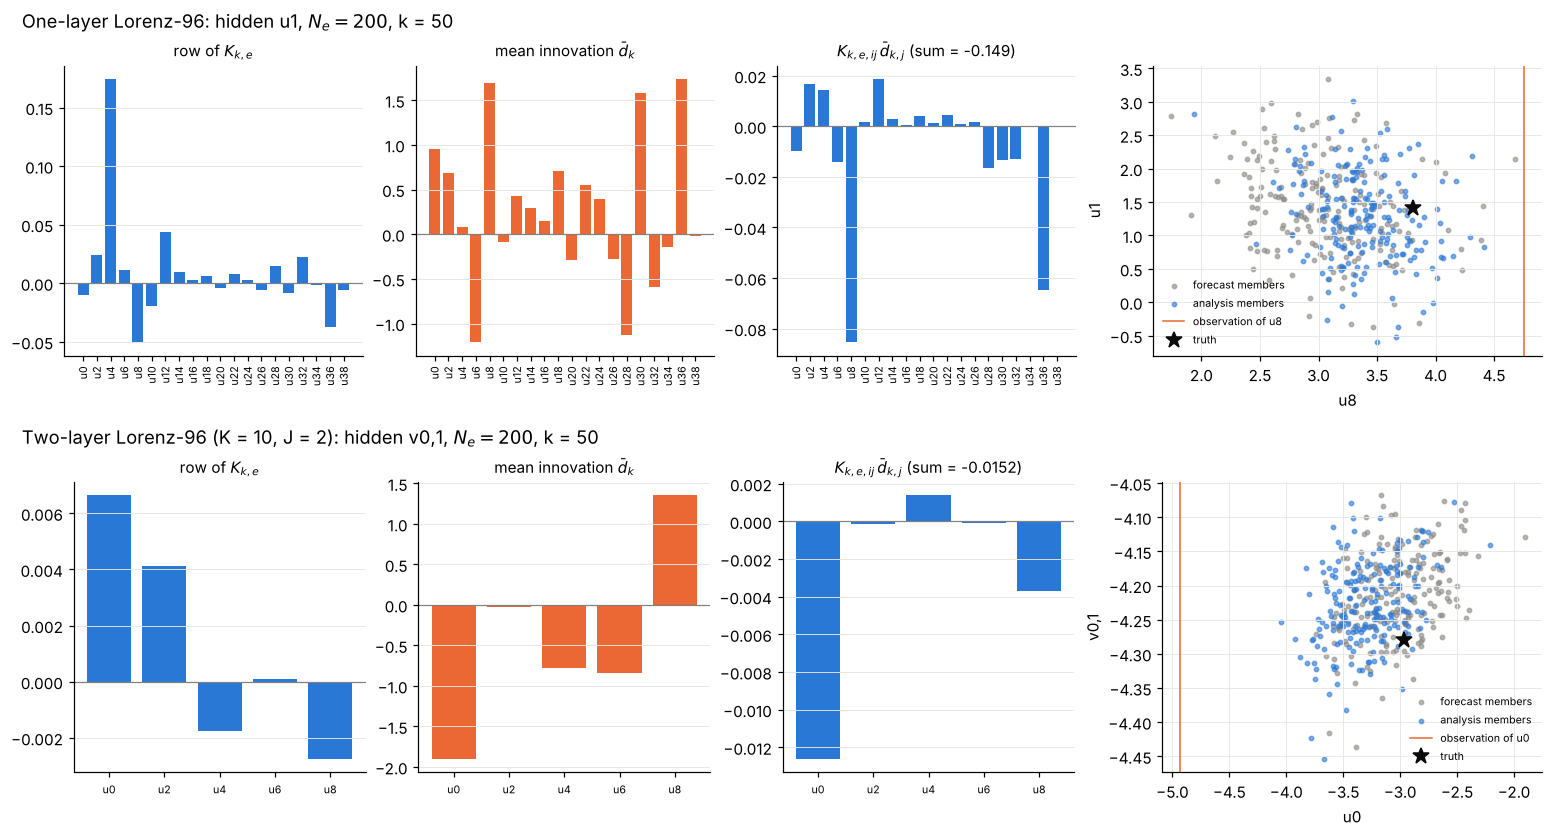

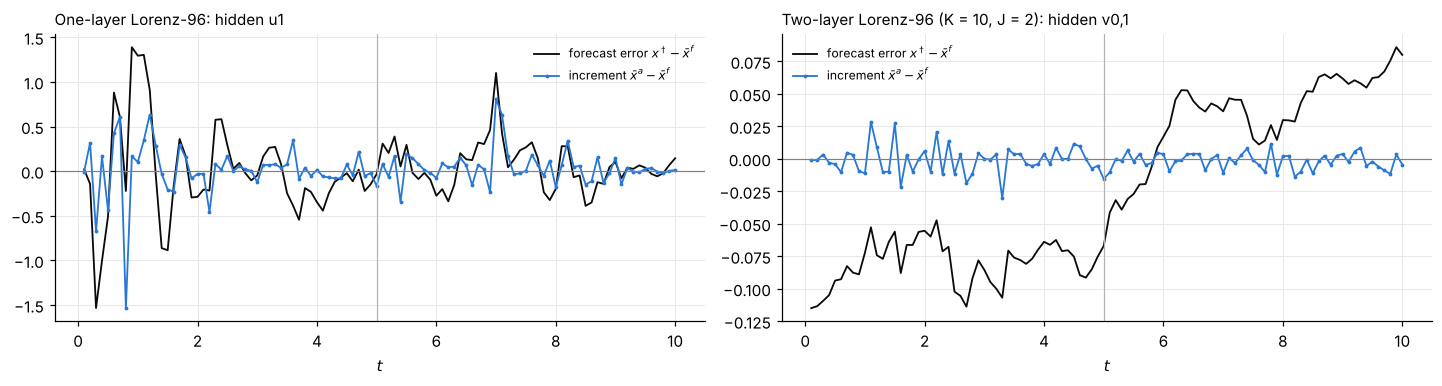

In [7]:
fig = plt.figure(figsize=(14, 7.5), constrained_layout=True)
sub = fig.subfigures(2, 1)
for s, (name, mdl) in enumerate(models.items()):
    o, tw = runs[(name, NE_SHOW, R_SHOW)], twins[name]
    k, i = K_SHOW, mdl["labels"].index(HIDDEN[name])
    obs = mdl["observed"]
    obs_labels = [mdl["labels"][j] for j in obs]
    row, d_bar = o["K"][k - 1][i], o["innovation_mean"][k - 1]
    contrib = row * d_bar
    jstar = int(np.argmax(np.abs(contrib)))                 # observed component that contributes most
    ax_K, ax_d, ax_c, ax_s = sub[s].subplots(1, 4, width_ratios=[1, 1, 1, 1.3])
    sub[s].suptitle(f"{mdl['title']}: hidden {HIDDEN[name]}, $N_e = {NE_SHOW}$, k = {k}", x=0.01, ha="left")
    x = np.arange(len(obs))
    ax_K.bar(x, row, color=C["mean"])
    ax_K.set_title("row of $K_{k,e}$", fontsize=10)
    ax_d.bar(x, d_bar, color=C["obs"])
    ax_d.set_title(r"mean innovation $\bar d_k$", fontsize=10)
    ax_c.bar(x, contrib, color=C["mean"])
    ax_c.set_title(rf"$K_{{k,e,ij}}\,\bar d_{{k,j}}$ (sum = {contrib.sum():.3g})", fontsize=10)
    for ax in (ax_K, ax_d, ax_c):
        ax.set_xticks(x, obs_labels, rotation=90 if len(x) > 8 else 0, fontsize=7)
        ax.axhline(0, color="0.5", lw=0.8)
        ax.grid(axis="x", visible=False)
    jj = obs[jstar]
    ax_s.scatter(o["E_f"][k][jj], o["E_f"][k][i], s=8, color=C["fc"], alpha=0.6, label="forecast members")
    ax_s.scatter(o["E_a"][k][jj], o["E_a"][k][i], s=8, color=C["an"], alpha=0.6, label="analysis members")
    ax_s.axvline(tw["Y"][k - 1][jstar], color=C["obs"], lw=1, label=f"observation of {obs_labels[jstar]}")
    ax_s.plot(tw["x_true"][k, jj], tw["x_true"][k, i], "*", color=C["truth"], ms=11, label="truth")
    ax_s.set_xlabel(obs_labels[jstar])
    ax_s.set_ylabel(HIDDEN[name])
    ax_s.legend(fontsize=7, loc="best")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4), constrained_layout=True)
for ax, (name, mdl) in zip(axes, models.items()):
    o, tw = runs[(name, NE_SHOW, R_SHOW)], twins[name]
    i = mdl["labels"].index(HIDDEN[name])
    ax.plot(t_obs, tw["x_true"][1:, i] - o["mean_f"][1:, i], color=C["truth"],
            label=r"forecast error $x^\dagger - \bar x^f$")
    ax.plot(t_obs, o["mean_a"][1:, i] - o["mean_f"][1:, i], ".-", color=C["mean"], ms=3,
            label=r"increment $\bar x^a - \bar x^f$")
    ax.axvline(t_an[K_SHOW], color="0.7", lw=0.8)
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_title(f"{mdl['title']}: hidden {HIDDEN[name]}", loc="left", fontsize=10)
    ax.set_xlabel("$t$")
    ax.legend(fontsize=8)
plt.show()

### Illustration: more members versus a different $R$

One forecast ensemble, no new filter runs and no new data: the $N_e = 200$, $r = 0$ forecast ensemble at $t_k$ from above. The hidden-component row of the gain is computed from

* all 200 members with the baseline $R$;
* each of the four disjoint 50-member subsets with the baseline $R$ (each subset is itself a sample of the same forecast distribution);
* all 200 members with $R/4$ and $4R$.

The printed analysis standard deviation of the hidden component is the one implied by each gain, $\big[(I - KH)P^f\big]_{ii}^{1/2}$, where $P^f$ is the same (sub)ensemble's sample covariance.

=== One-layer Lorenz-96: hidden u1, k = 50; forecast sd 0.6959 ===
  50-member subset 0, R   : analysis sd 0.6996
  50-member subset 1, R   : analysis sd 0.6035
  50-member subset 2, R   : analysis sd 0.5997
  50-member subset 3, R   : analysis sd 0.6607
  all 200 members, 1 R : analysis sd 0.6603
  all 200 members, 0.25 R : analysis sd 0.5959
  all 200 members, 4 R : analysis sd 0.6854

=== Two-layer Lorenz-96 (K = 10, J = 2): hidden v0,1, k = 50; forecast sd 0.0629 ===
  50-member subset 0, R   : analysis sd 0.0599
  50-member subset 1, R   : analysis sd 0.0539
  50-member subset 2, R   : analysis sd 0.0678
  50-member subset 3, R   : analysis sd 0.0668
  all 200 members, 1 R : analysis sd 0.0623
  all 200 members, 0.25 R : analysis sd 0.0609
  all 200 members, 4 R : analysis sd 0.0627



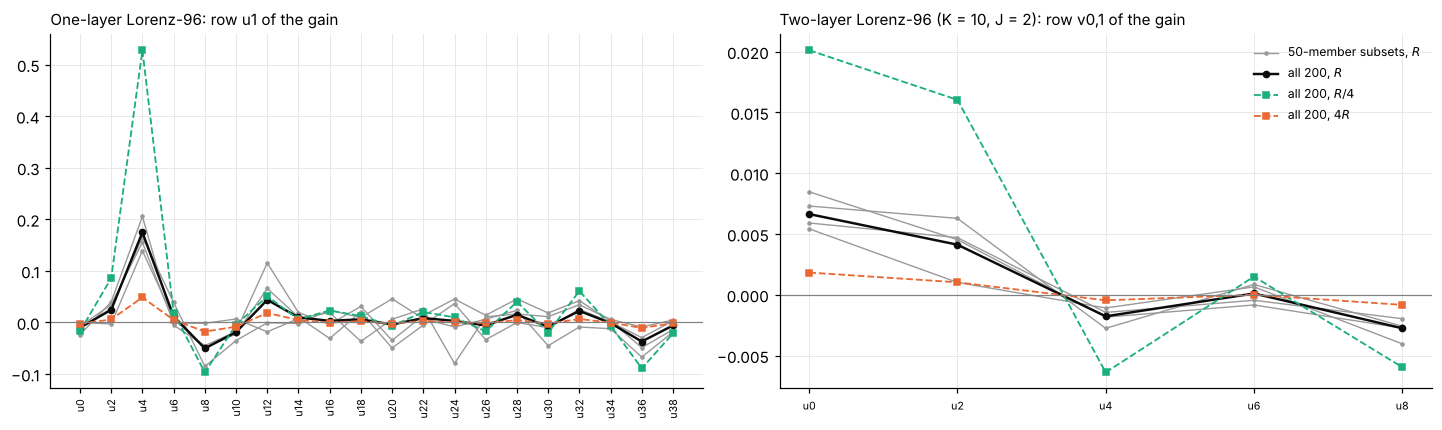

In [8]:
def gain_and_sd(E, R, H, i):
    _, P = ensemble_mean_cov(E)
    S = H @ P @ H.T + R
    K = np.linalg.solve(S, H @ P).T
    var_a = P[i, i] - K[i] @ (H @ P[:, i])
    return K[i], np.sqrt(var_a)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), constrained_layout=True)
for ax, (name, mdl) in zip(axes, models.items()):
    o = runs[(name, NE_SHOW, R_SHOW)]
    Ef = o["E_f"][K_SHOW]
    i = mdl["labels"].index(HIDDEN[name])
    H, R = mdl["H"], mdl["R"]
    x = np.arange(H.shape[0])
    obs_labels = [mdl["labels"][j] for j in mdl["observed"]]
    print(f"=== {mdl['title']}: hidden {HIDDEN[name]}, k = {K_SHOW}; forecast sd "
          f"{np.sqrt(ensemble_mean_cov(Ef)[1][i, i]):.4f} ===")
    Ne_all = Ef.shape[1]
    for q, idx in enumerate(np.array_split(np.arange(Ne_all), 4)):
        row, sd_a = gain_and_sd(Ef[:, idx], R, H, i)
        ax.plot(x, row, ".-", color="0.6", lw=0.9, ms=4, label=f"{len(idx)}-member subsets, $R$" if q == 0 else None)
        print(f"  {len(idx)}-member subset {q}, R   : analysis sd {sd_a:.4f}")
    for scale, color, lab in [(1.0, C["truth"], f"all {Ne_all}, $R$"), (0.25, "#1baf7a", f"all {Ne_all}, $R/4$"),
                              (4.0, C["obs"], f"all {Ne_all}, $4R$")]:
        row, sd_a = gain_and_sd(Ef, scale * R, H, i)
        ax.plot(x, row, "o-" if scale == 1.0 else "s--", color=color, lw=1.6 if scale == 1.0 else 1.2,
                ms=4, label=lab)
        print(f"  all {Ne_all} members, {scale:g} R : analysis sd {sd_a:.4f}")
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_xticks(x, obs_labels, rotation=90 if len(x) > 8 else 0, fontsize=7)
    ax.set_title(f"{mdl['title']}: row {HIDDEN[name]} of the gain", loc="left", fontsize=10)
    print()
axes[1].legend(fontsize=8)
plt.show()

**Answer to 3(b).** *Explain the roles of the forecast ensemble covariance and the observation perturbations. Use the hidden-state row of one ensemble gain and the innovations (above) to explain the hidden-state update. Discuss the difference between increasing $N_e$ and changing $R$.*



## AI use (draft — edit as needed)

Claude (Anthropic) helped write and debug the code for Problem 3: the ensemble-ready Lorenz–96 right-hand sides, the failure records added to `enkf.py`, additions to `hw8.py`, and the code cells in this notebook. The answer to 3(b) is my own.